# Week 2 — the claims domain and EDA

You will make the plots from today's slides on **your own cohort**, and write
one short sentence under each one. That sentence is the deliverable, not the
plot.

| TODO | You make | Slide |
|---|---|---|
| 1 | Rows vs. members in each file | *Three files, joined on member_id* |
| 2 | Plan-paid on a linear and a log axis | *Look at the shape of the money first* |
| 3 | Share of spend held by the top X% | *How much spend sits with the top few?* |
| 4–5 | Prevalence, then prevalence as the line moves | *Find your prevalence before accuracy* |
| 6 | High-cost rate by group, with intervals | *Compare groups with intervals, not bars* |
| 7 | "Known on day one?" for every column | *On the day I need this prediction…* |
| 8 | Four data checks | *Run four checks before you trust a figure* |

**Run:**

```bash
pip install -r requirements-dev.txt
jupyter notebook notebooks/week-02-eda.ipynb
```

**How each TODO works**

- **Hints:** which columns and which pandas call. Not the answer.
- **What you should see:** a *range*. Your seed gives you your own cohort, so
  your numbers won't match your neighbour's. Outside the range means something
  is wrong.
- **Your conclusion:** fill in the `______`. One sentence is enough.

Each TODO cell stands on its own, so you can work them in any order.

---

## 0. Setup

In [4]:
# Given — nothing to do here.
import os
import random
import sys
import uuid
from pathlib import Path

# Notebooks have no __file__, and every script in this repo assumes the repo
# root is the working directory. Walk up until we find config.py.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config.py").exists()), None)
if ROOT is None:
    raise RuntimeError(
        f"No config.py in {Path.cwd()} or any directory above it. Run this "
        "notebook from inside your clone of the repo."
    )
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from config import HIGH_COST_THRESHOLD_USD, STUDENT_SEED


def cohort_is_current() -> bool:
    """Is the data in data/ the cohort THIS seed produces?"""
    if not (Path("data/members.csv").exists()
            and Path("data/member_summary.csv").exists()):
        return False
    random.seed(STUDENT_SEED)
    expected_first_id = str(uuid.UUID(int=random.getrandbits(128), version=4))
    on_disk = pd.read_csv("data/members.csv", nrows=1).iloc[0]["member_id"]
    return on_disk == expected_first_id


# The data is gitignored, so make it when it is missing or from another seed.
if not cohort_is_current():
    print(f"Generating the cohort for STUDENT_SEED={STUDENT_SEED} ...")
    from generate_claims_data import generate

    generate()
    print()

# procedure_code holds CPT codes. Read them as text, or "99213" becomes 99213.0.
members = pd.read_csv("data/members.csv")
claims = pd.read_csv("data/claims.csv", dtype={"procedure_code": "string"})
summary = pd.read_csv("data/member_summary.csv")

assert cohort_is_current(), "data/ does not match STUDENT_SEED — regenerate it"
print(f"STUDENT_SEED        {STUDENT_SEED}")
print(f"dollar threshold    ${HIGH_COST_THRESHOLD_USD:,}")
print(f"members / claims    {len(members):,} / {len(claims):,}")

STUDENT_SEED        4
dollar threshold    $25,000
members / claims    2,000 / 21,227


If the seed printed above is not the one you were assigned, stop and fix it
first — see *Your own cohort* in the README.

In [5]:
# Given — nothing to do here. Use these helpers; don't rewrite them.
BLUE, ORANGE = "#2a78d6", "#eb6834"      # orange = high-cost, everywhere
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e2e1dd"

sns.set_theme(context="notebook", style="whitegrid")
plt.rcParams.update({
    "axes.edgecolor": GRID,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": GRID,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def dollars(cents):
    """Cents -> dollars. Every money column in this dataset is in cents."""
    return cents / 100


def usd(x, _pos=None):
    """Axis-tick formatter: ax.xaxis.set_major_formatter(plt.FuncFormatter(usd))."""
    for cut, suffix in ((1e6, "M"), (1e3, "k")):
        if abs(x) >= cut:
            scaled = x / cut
            digits = 0 if scaled == int(scaled) else 1
            return f"${scaled:,.{digits}f}{suffix}"
    return f"${x:,.0f}"


def threshold_line(ax, x=None):
    """Draw the $ dollar threshold as a dashed, labelled vertical line."""
    x = HIGH_COST_THRESHOLD_USD if x is None else x
    ax.axvline(x, color=MUTED, linewidth=1.2, linestyle="--", zorder=1)
    ax.annotate(f"dollar threshold ${x:,}", xy=(x, 1),
                xycoords=("data", "axes fraction"), xytext=(4, -12),
                textcoords="offset points", color=MUTED, fontsize=9)


def wilson_interval(k, n, z=1.96):
    """
    95% interval for a rate k/n. Returns (lo, hi).

    Works on single numbers or on whole columns at once:
        table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
    """
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)


def plot_rates(table, ax, title):
    """
    One row per group: a dot for the rate and a line for its 95% interval.
    The dashed line is the rate for the whole cohort.

    `table` needs columns rate, lo and hi, with the group names as its index.
    """
    y = np.arange(len(table))[::-1]
    ax.hlines(y, table["lo"], table["hi"], color=BLUE, linewidth=2)
    ax.plot(table["rate"], y, "o", color=BLUE)
    ax.axvline(summary["is_high_cost"].mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.set_yticks(y, table.index)
    ax.set(title=title, xlabel="high-cost rate (95% interval)", xlim=(0, 0.13))
    ax.set_xticks([0, 0.04, 0.08, 0.12])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))


# Plan-paid per member, in dollars. Most TODOs start from this.
paid = dollars(summary["total_plan_paid_cents"])

DEMOGRAPHIC_COLUMNS = ["age_bucket", "sex", "region"]
AGE_ORDER = ["18-29", "30-39", "40-49", "50-59", "60-64"]

print("Helpers are ready.")

Helpers are ready.


---

## 1. Why we are doing this

Three teams could act on a high-cost prediction: **care management** (who do we
call?), **reserves** (how much money do we set aside?) and **pricing** (what do
we charge next year?). You'll pick yours in Week 5.

Whichever you pick, two things are already true:

1. **High-cost members are rare.** Most members cost very little.
2. **The prediction has to be made before the spending happens.** On January 1,
   not December 31.

Every TODO below checks one of those, or checks that the data is safe to use.

---

## 2. Three files, joined on `member_id`

First, find out what one row means in each file.

In [6]:
# ---------------------------------------------------------------------------
# TODO 1 — what does one row mean?
#
# For members, claims and summary, print the number of rows and the number
# of DISTINCT member_ids. If the two differ, one row is not one member.
# Then look at a few rows of claims.
#
# Docs that will help:
#   - DataFrame.shape (or Python's len)
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html
#   - Series.nunique
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.nunique.html
#   - DataFrame.head  (tip: add .T to read wide tables)
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html
# ---------------------------------------------------------------------------

# your code here
memberShape = pd.DataFrame(members)
memberUnique = memberShape["member_id"].nunique()

claimsShape=pd.DataFrame(claims)
claimsUnique = claimsShape["member_id"].nunique()

summaryShape=pd.DataFrame(summary)
summaryUnique = summaryShape["member_id"].nunique()


print("Members has",memberShape.shape[0], "rows with", memberUnique, "unique IDs")
print("Claims has", claimsShape.shape[0], "rows with", claimsUnique, "unique IDs")
print("Summary has", summaryShape.shape[0], "rows with", summaryUnique, "unique IDs")

# Conclusion
# With members being represented multiple times (having mutliple claims), we can have the same member in both testing and training splits
# as well as a specific person contributing multiple times more than another individual.
# Our model is trying to predict high-cost predictions, not by individual claims

Members has 2000 rows with 2000 unique IDs
Claims has 21227 rows with 2000 unique IDs
Summary has 2000 rows with 2000 unique IDs


**What you should see.** `members` and `summary` have one row per member (2,000
rows, 2,000 members). `claims` has about 10–12 rows per member.

**Your conclusion**: why can't a model train on `claims.csv` as it is?

> ______

---

## 3. The shape of the money

`total_plan_paid_cents` is what the plan paid for a member over the year. It is
the number this whole project is about.

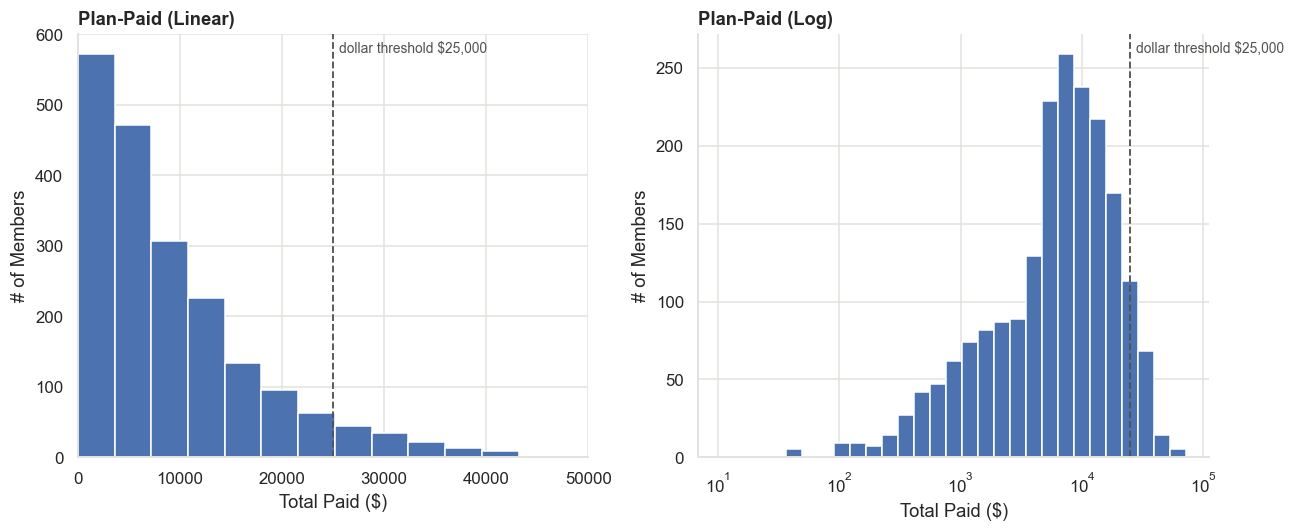

In [15]:
# ---------------------------------------------------------------------------
# TODO 2 — plot plan-paid per member on a linear axis, then a log axis.
#
# Two histograms side by side, with the dollar threshold on both. Then
# print the mean and the median.
#
# Given: `paid` (dollars per member) and threshold_line(ax), both in the
# helpers cell. A log axis can't show $0, so leave zeros out of that panel,
# and space the bins evenly in log terms rather than in dollars.
#
# Docs that will help:
#   - pyplot.subplots
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html
#   - Axes.hist
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html
#   - Axes.set_xscale
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xscale.html
#   - numpy.logspace
#     https://numpy.org/doc/stable/reference/generated/numpy.logspace.html
#   - Series.mean / Series.median
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.median.html
# ---------------------------------------------------------------------------

# your code here
paid = summary["total_plan_paid_cents"] / 100

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

#linear
ax[0].hist(paid, bins=20)
ax[0].set_title("Plan-Paid (Linear)")
ax[0].set_xlabel("Total Paid ($)")
ax[0].set_ylabel("# of Members")
ax[0].set_xlim(0,50000)
threshold_line(ax[0])

#logarithmic
positive_paid = paid[paid > 0]

bins = np.logspace(
    np.log10(positive_paid.min()),
    np.log10(positive_paid.max()),
    30
)

ax[1].hist(positive_paid, bins=bins)
ax[1].set_xscale("log")
ax[1].set_title("Plan-Paid (Log)")
ax[1].set_xlabel("Total Paid ($)")
ax[1].set_ylabel("# of Members")
threshold_line(ax[1])

plt.tight_layout()
plt.show()






**What you should see.** On the linear axis, most members are squeezed to the
left and a long tail stretches to the right. On the log axis the shape is easy
to read. The mean is higher than the median (median around $6k–9k).

**Your conclusion**: which number better describes a typical member, the mean or the median? Why?

> ______

### How much spend sits with the top few?

Last week: in real US healthcare, the costliest 5% of people drive about half
of all spending. Check whether your cohort looks like that.

In [ ]:
# ---------------------------------------------------------------------------
# TODO 3 — share of total spend held by the top X% of members.
#
# Sort members from most to least expensive. Plot the running share of
# total spend (y) against the share of members counted so far (x). Add a
# dashed diagonal for "everyone costs the same". Then print the share
# held by the top 5%, 10% and 20%.
#
# Docs that will help:
#   - numpy.sort  (it sorts ascending; how do you reverse it?)
#     https://numpy.org/doc/stable/reference/generated/numpy.sort.html
#   - numpy.cumsum
#     https://numpy.org/doc/stable/reference/generated/numpy.cumsum.html
#   - numpy.arange
#     https://numpy.org/doc/stable/reference/generated/numpy.arange.html
#   - Axes.plot  (see the linestyle argument)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html
# ---------------------------------------------------------------------------

# your code here

**What you should see.** A curve that bows above the diagonal. The top 20% of
members hold roughly 45–52% of spend.

**Your conclusion**: your top 5% hold ___% of spend. Is that more or less than the ~50% in real life?

> ______

---

## 4. The label is a line someone drew

`is_high_cost` is 1 when a member's plan-paid is over the **dollar threshold**
(`HIGH_COST_THRESHOLD_USD` in `config.py`, $25,000). It is a choice, not a fact
about the member.

In [ ]:
# ---------------------------------------------------------------------------
# TODO 4 — your prevalence.
#
# Print how many members are high-cost, and what share of all members that
# is. Then print the accuracy of a "model" that predicts nobody is
# high-cost. (Who would that model get right?)
#
# Docs that will help:
#   - Series.sum
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.sum.html
#   - Series.mean  (the mean of a 0/1 column is a share)
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.mean.html
# ---------------------------------------------------------------------------

# your code here

**What you should see.** A prevalence between 4% and 9%, so predicting nobody
scores 91%–96% accuracy.

**Your conclusion**: a classmate says their model is 94% accurate. Why isn't that impressive here?

> ______

### What if the line were somewhere else?

$25,000 is a choice. In TODO 4 you asked "what share of members cost more than
$25k?" Now ask the same question for other dollar amounts, from $2,500 up to
$60,000, and plot the answers.

Think of the bar for calling someone "tall": set it at 5 feet and nearly
everyone is tall; set it at 7 feet and almost nobody is.

In [ ]:
# ---------------------------------------------------------------------------
# TODO 5 — move the line.
#
# Worked example: the share of members who cost more than $5,000.
#
#     paid > 5_000              -> True/False for every member
#     (paid > 5_000).mean()     -> the share that are True (True counts as 1)
#     (paid > 5_000).sum()      -> the NUMBER that are True
#
# Your steps:
#   1. Make a list to hold your answers:   shares = []
#   2. Loop over `lines` (given below). For each one, work out the share of
#      members above it, the same way as the example, and append it.
#   3. Print each line next to its share, so you can read off $10,000.
#   4. Plot `lines` (x) against `shares` (y) with ax.plot, add dots with
#      marker="o", and call threshold_line(ax) to mark $25k.
#   5. Print the NUMBER of members above $50,000.
#
# Docs that will help:
#   - Comparing a Series to a number gives True/False
#     https://pandas.pydata.org/docs/user_guide/indexing.html#boolean-indexing
#   - Python for loops and list.append
#     https://docs.python.org/3/tutorial/controlflow.html#for-statements
#   - Axes.plot  (see the marker argument)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html
# ---------------------------------------------------------------------------

lines = [2_500, 5_000, 10_000, 15_000, 20_000, 25_000, 30_000, 40_000, 50_000, 60_000]

# your code here

**What you should see.** A curve that starts high and drops fast. At $10k,
30–45% of members are over the line; above $50k, only a handful of *members*
(a count, not a percentage).

**Your conclusion**: what goes wrong if the line is set much lower, or much higher?

> ______

---

## 5. Do some groups have more high-cost members?

**The question.** Are older members more likely to be high-cost than younger
ones? Women more than men? One region more than another?

**Step 1: the rate.** For each group, divide the high-cost members by all the
members in that group. 20 high-cost out of 400 members is a rate of 5%.

**Step 2: why a rate on its own can fool you.** High-cost members are rare, so
each group only has a few dozen of them. With numbers that small, luck moves
the rate a lot. Two groups can look different when the gap is just chance.

Think of coin flips: 7 heads in 10 flips doesn't prove a coin is unfair, but
700 heads in 1,000 flips does. The more flips, the more you can trust the
result.

**Step 3: the 95% interval.** This is the range the group's *true* rate
probably sits in, given how many members we have. Fewer members means a wider
range. Both of these are 5%, but we're much surer about the second:

| High-cost / members | Rate | 95% interval |
|---|---|---|
| 5 / 100 | 5% | 2.2% to 11.2% |
| 50 / 1,000 | 5% | 3.8% to 6.5% |

**How to read the plot.** Each group gets one row:

```
            0%        5%        10%
Group A        |----●----|                ● = the group's rate
Group B             |------●------|       |--| = its 95% interval
                     ¦                    ¦ (dashed) = rate for everyone
```

- **The lines overlap:** you can't say the groups differ. The gap could be luck.
- **The lines don't overlap:** the difference is probably real.

Example: Group A is 20 / 400 = 5% (3.3% to 7.6%). Group B is 30 / 400 = 7.5%
(5.3% to 10.5%). B looks higher, but the ranges overlap, so you **can't** claim
a difference.

**What you'll write.** For each variable, one of two sentences:

- "*X* has a higher rate than *Y*, and their intervals don't overlap."
- "No detectable difference at this sample size."

The second one is a complete answer. It does **not** mean "there is no
difference"; it means we don't have enough members to tell.

**Why it matters.** If the data has a real gap between groups, a model trained
on it will learn that gap too. Week 6 asks whether that's fair.

In [ ]:
# ---------------------------------------------------------------------------
# TODO 6 — high-cost rate by group, with 95% intervals.
#
# Worked example: count members and high-cost members in each age bucket.
#
#     table = summary.groupby("age_bucket")["is_high_cost"].agg(n="size", positives="sum")
#
#   n         = members in the group
#   positives = high-cost members (is_high_cost is 0/1, so the sum counts the 1s)
#
# Your steps, starting with age_bucket:
#   1. Run the worked example. Then put the buckets in order:
#          table = table.reindex(AGE_ORDER)
#   2. Add a "rate" column: positives divided by n.
#   3. Add "lo" and "hi" columns with the given helper:
#          table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
#   4. print(table), then plot it with the given helper:
#          fig, ax = plt.subplots(figsize=(5, 3))
#          plot_rates(table, ax, "age_bucket")
#   5. Do the same for "sex" and "region". Skip the reindex step; those
#      groups have no natural order.
#
# Docs that will help:
#   - DataFrame.groupby
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html
#   - Adding a new column from existing ones
#     https://pandas.pydata.org/docs/getting_started/intro_tutorials/05_add_columns.html
#   - Series.reindex
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html
# ---------------------------------------------------------------------------

# your code here

**What you should see.** `sex` and `region` rates within a few points of each
other, with intervals that overlap. `age_bucket` usually rises with age, but in
some cohorts even age is too close to call.

**Your conclusion**: which variable, if any, shows a difference you can defend? For the others, write "no detectable difference at this sample size".

> ______

---

## 6. One question for every column

The prediction is made on **January 1**. The label is only known after
**December 31**. So, for each column in `member_summary.csv`:

> **"On the day I need this prediction, do I already know this number?"**

**TODO 7: fill in the last column.** No code. Write *Yes*, *No* or
*Debatable*, and a few words of why. Look at how each column is defined, not at
how well it correlates with the label.

- **Yes:** you'd know it on January 1.
- **No:** it's the outcome, or nearly the same number as the outcome.
- **Debatable:** you'd know a version of it on January 1, but this column was
  measured over the same year as the label.

| Column | What it is | Known on day one? |
|---|---|---|
| `age_bucket` | banded age |  |
| `sex` | recorded sex |  |
| `region` | US region |  |
| `total_claims` | approved claims in the year |  |
| `medical_claims` | of those, non-pharmacy |  |
| `pharmacy_claims` | of those, pharmacy |  |
| `specialty_drug_fills` | specialty fills in the year |  |
| `total_billed_cents` | what providers billed |  |
| `total_allowed_cents` | what the plan allowed |  |
| `total_plan_paid_cents` | what the plan paid |  |
| `total_oop_cents` | what the member paid |  |
| `unique_diagnosis_codes` | distinct diagnoses seen |  |
| `inpatient_claims` | institutional claims |  |
| `has_specialty_drug` | any specialty fill |  |
| `is_high_cost` | the label |  |

Hint: this data covers one plan year. A real system would use *last* year's
claims to predict *this* year. Which columns could you get from last year?

**Your conclusion**: which row was hardest to decide, and why?

> ______

`tests/test_leakage.py` fails until Weeks 3–4. That is on purpose, and this
table is what it is about.

---

## 7. Four checks before you trust a figure

In [ ]:
# ---------------------------------------------------------------------------
# TODO 8a — missing or structural?
#
# Print the share of blanks in each column of claims that has any. Then
# compare those shares with the share of claims that are pharmacy.
#
# Docs that will help:
#   - DataFrame.isna
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html
#   - DataFrame.mean
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html
# ---------------------------------------------------------------------------

# your code here

**What you should see.** No blanks in `members` or `summary`. In `claims`, some
columns blank on about 23% of rows and others on about 77%.

**Your conclusion**: is a blank `diagnosis_code` on a pharmacy claim missing data? What would go wrong if you filled it in?

> ______

In [ ]:
# ---------------------------------------------------------------------------
# TODO 8b — does the money add up?
#
# Every claim should satisfy  plan_paid + out_of_pocket == allowed.
# Print the share of claims where it holds, for each claim_type.
#
# Docs that will help:
#   - Arithmetic and comparisons on columns
#     https://pandas.pydata.org/docs/user_guide/basics.html#flexible-binary-operations
#   - Series.groupby
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.groupby.html
# ---------------------------------------------------------------------------

# your code here

**What you should see.** The identity holds for most medical claims and for
**none** of the pharmacy claims.

**Your conclusion**: the identity fails on some claims. Why does that matter before you build features from these columns?

> ______

In [ ]:
# ---------------------------------------------------------------------------
# TODO 8c — do the counts match?
#
# For each member, does summary's total_claims equal (i) ALL their claims,
# or (ii) only their APPROVED claims? Print the share of members that match
# each. Members with no claims at all should count as 0, not be dropped.
#
# Docs that will help:
#   - DataFrameGroupBy.size
#     https://pandas.pydata.org/docs/reference/api/pandas.api.typing.DataFrameGroupBy.size.html
#   - DataFrame.set_index
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.set_index.html
#   - Series.reindex  (see fill_value)
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html
# ---------------------------------------------------------------------------

# your code here

**What you should see.** One of the two matches for 100% of members.

**Your conclusion**: which claims does `member_summary.csv` count, and why?

> ______

In [ ]:
# ---------------------------------------------------------------------------
# TODO 8d — any time pattern?
#
# Plot the number of claims in each month of service_date, as a line.
# Start the y axis at 0 so small wiggles don't look big.
#
# Docs that will help:
#   - pandas.to_datetime
#     https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
#   - Series.dt.month
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.month.html
#   - Series.value_counts and Series.sort_index
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html
#   - Axes.set  (ylim=...)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set.html
# ---------------------------------------------------------------------------

# your code here

**What you should see.** A roughly flat line.

**Your conclusion**: is there a seasonal pattern? What does that mean for features like "month of first claim"?

> ______

---

## 8. What to carry into Week 3

Fill in your numbers. These are the start of your Week 8 slides.

**The prediction target**

| | |
|---|---|
| Label column | `______` |
| It is 1 when | `______` is over $______ |
| Measured over | ______ |
| Predicted on | ______, before ______ |
| Kind of problem | ______ (regression or classification?) |

**Your cohort**

| Finding | Your number |
|---|---|
| Claims rows per member | ______ |
| Median vs. mean plan-paid | $______ vs. $______ |
| Share of spend held by the top 5% | ______ % |
| Prevalence at $25k | ______ % |
| Accuracy of predicting nobody | ______ % |
| Columns marked Yes / Debatable / No | ______ / ______ / ______ |

## Before you open your PR

- [ ] `pytest tests/test_data.py -v` — nine passing
- [ ] Every `______` is filled in
- [ ] **Kernel → Restart & Run All** works top to bottom
- [ ] The seed printed in section 0 is the one you were assigned
- [ ] Nothing in `data/` is staged — `git status` should not list it

Then commit the notebook, open a PR, and review your partner's. Their seed is
different, so ask how they got their numbers rather than comparing values.

In [4]:
import sys
import site

print("Site packages:", site.getsitepackages())
print("Python paths:")
for path in sys.path:
    print(path)

Site packages: ['/Users/jaysteezy/Documents/Development/Claims Cost Predictor/.venv/lib/python3.11/site-packages']
Python paths:
/Users/jaysteezy/Documents/Development/Claims Cost Predictor/claims-cost-predictor
/opt/homebrew/Cellar/python@3.11/3.11.17/Frameworks/Python.framework/Versions/3.11/lib/python311.zip
/opt/homebrew/Cellar/python@3.11/3.11.17/Frameworks/Python.framework/Versions/3.11/lib/python3.11
/opt/homebrew/Cellar/python@3.11/3.11.17/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload

/Users/jaysteezy/Documents/Development/Claims Cost Predictor/.venv/lib/python3.11/site-packages
